In [4]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = 'ESA-Mission1'
PRE_DIR, FULL_DIR = 'plots/pre_anomaly', 'plots/full_anomaly'
os.makedirs(PRE_DIR, exist_ok=True)
os.makedirs(FULL_DIR, exist_ok=True)

# A pre-anomaly window needs at least MIN_SAMPLES points and no gap longer than MAX_GAP
MIN_SAMPLES = 10
MAX_GAP = pd.Timedelta(minutes=10)

In [5]:
# Pick actual anomalies (no rare events or communication gaps) from three classes
labels = pd.read_csv(f'{DATA_DIR}/labels.csv', parse_dates=['StartTime', 'EndTime'])
types = pd.read_csv(f'{DATA_DIR}/anomaly_types.csv')
actual = types[types.Category == 'Anomaly']
anomalies = pd.concat([actual[actual.Class == c].sample(n, random_state=0)
                       for c, n in [('class_7', 4), ('class_3', 3), ('class_22', 3)]])
anomalies

,ID,Class,Subclass,Category,Dimensionality,Locality,Length
136,id_137,class_7,subclass_1,Anomaly,Multivariate,Local,Subsequence
160,id_161,class_7,subclass_1,Anomaly,Multivariate,Local,Subsequence
126,id_127,class_7,subclass_1,Anomaly,Multivariate,Local,Subsequence
5,id_6,class_7,subclass_1,Anomaly,Multivariate,Local,Subsequence
90,id_91,class_3,subclass_2,Anomaly,Multivariate,Local,Subsequence
185,id_186,class_3,subclass_2,Anomaly,Multivariate,Global,Subsequence
129,id_130,class_3,subclass_2,Anomaly,Multivariate,Global,Point
61,id_62,class_22,subclass_3,Anomaly,Univariate,Global,Subsequence
66,id_67,class_22,subclass_1,Anomaly,Univariate,Global,Subsequence
143,id_144,class_22,subclass_1,Anomaly,Univariate,Local,Subsequence


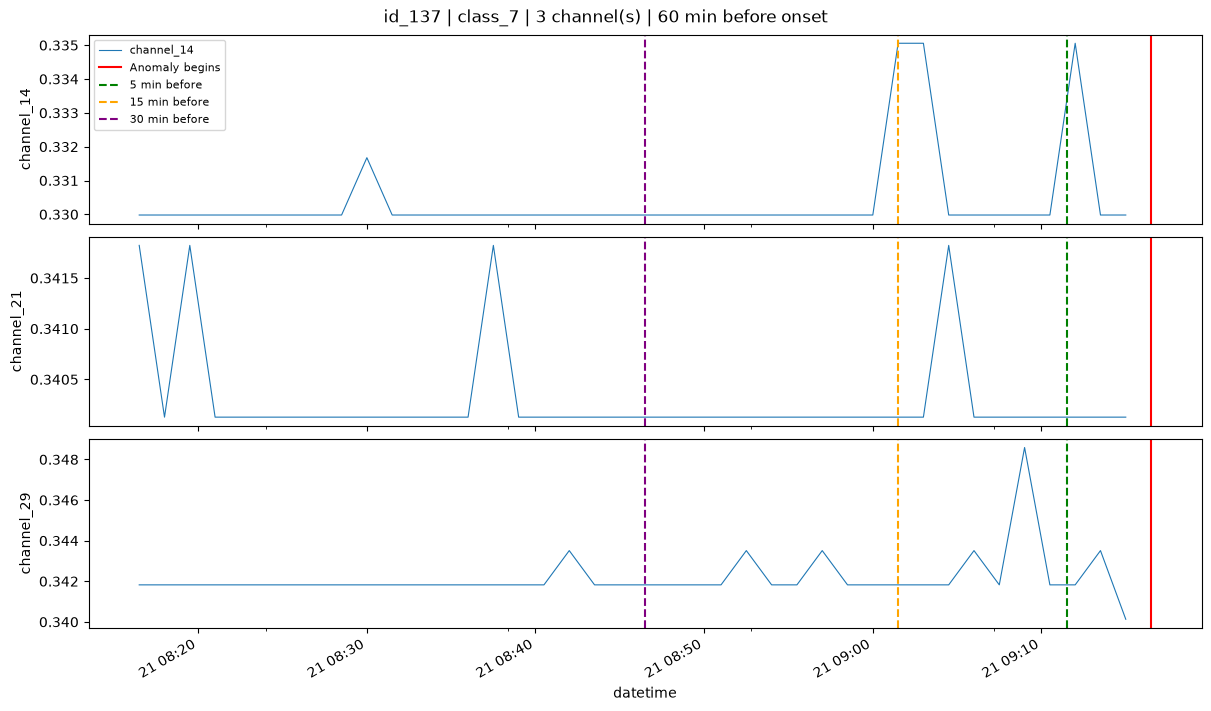

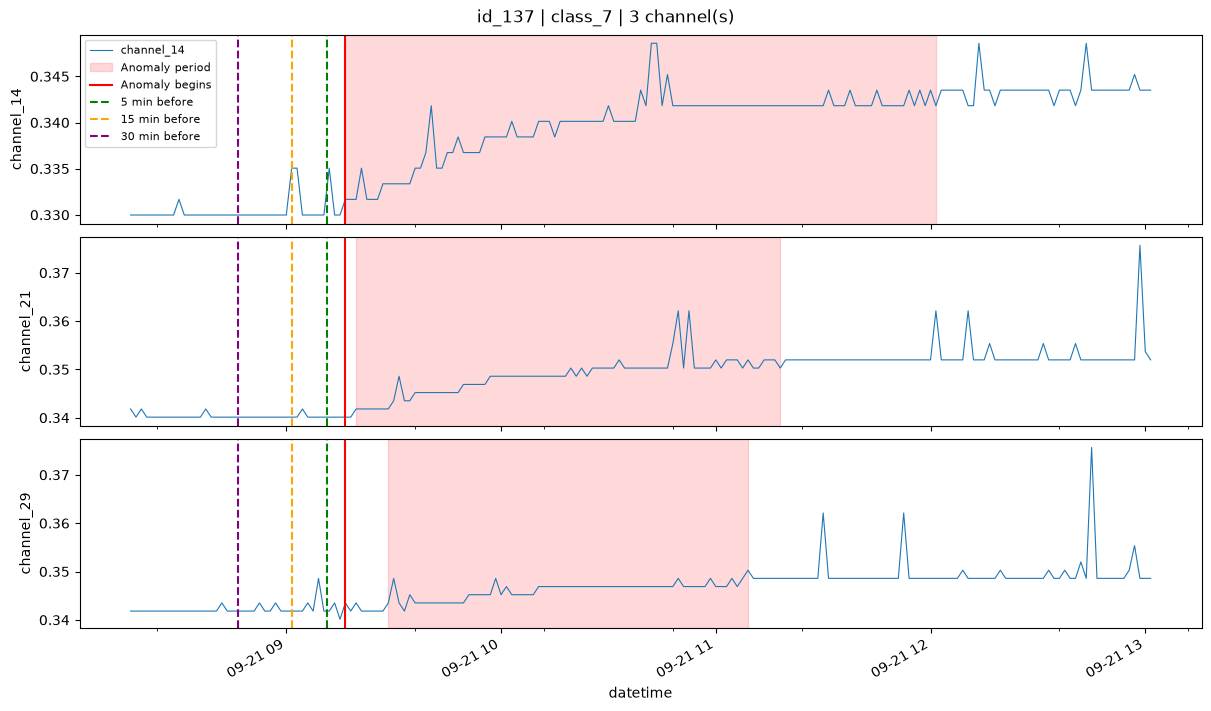

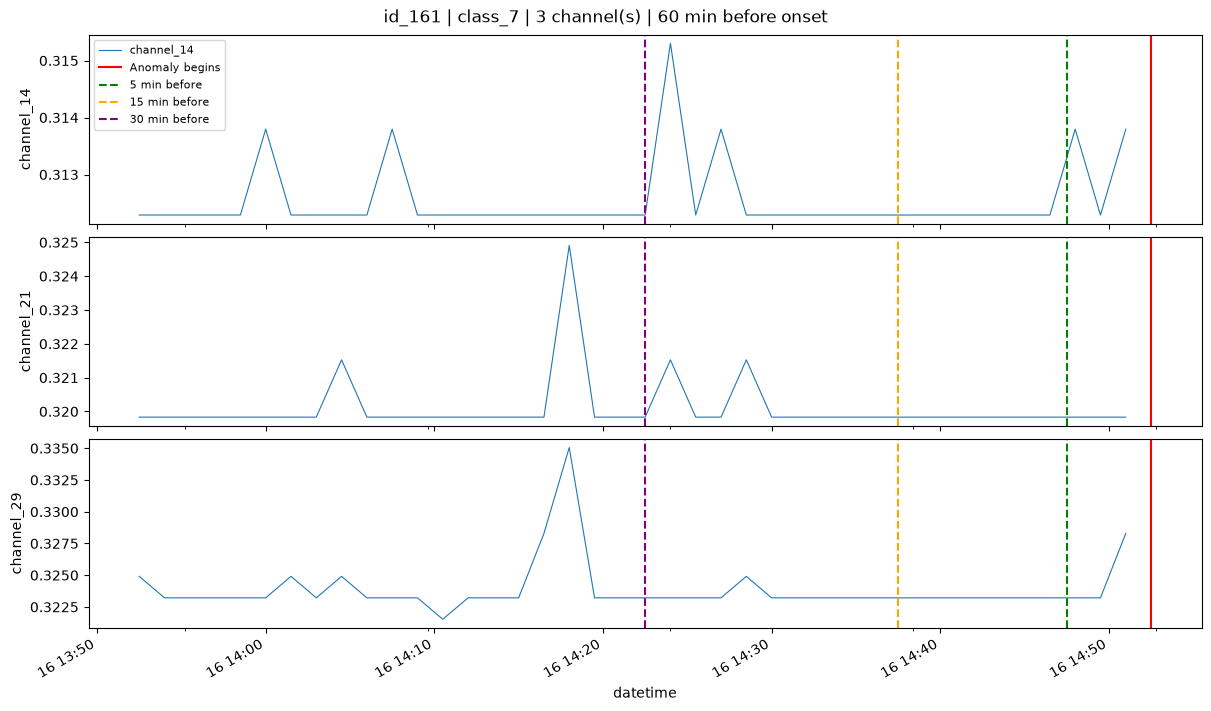

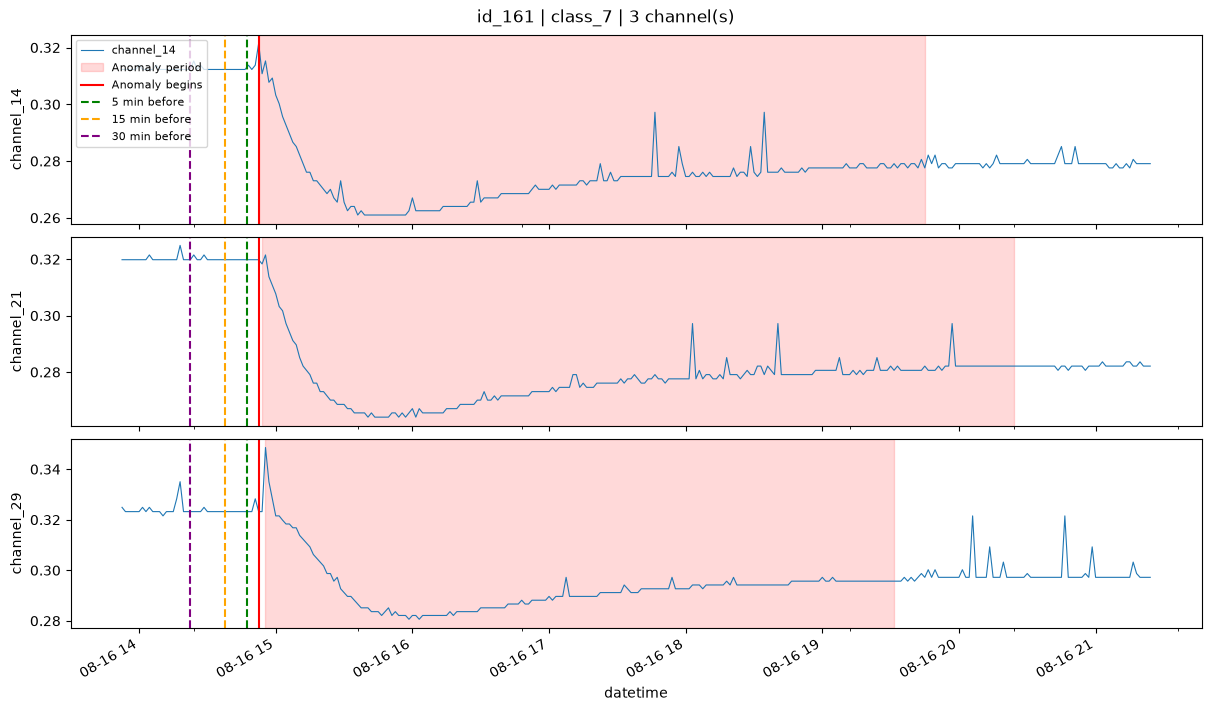

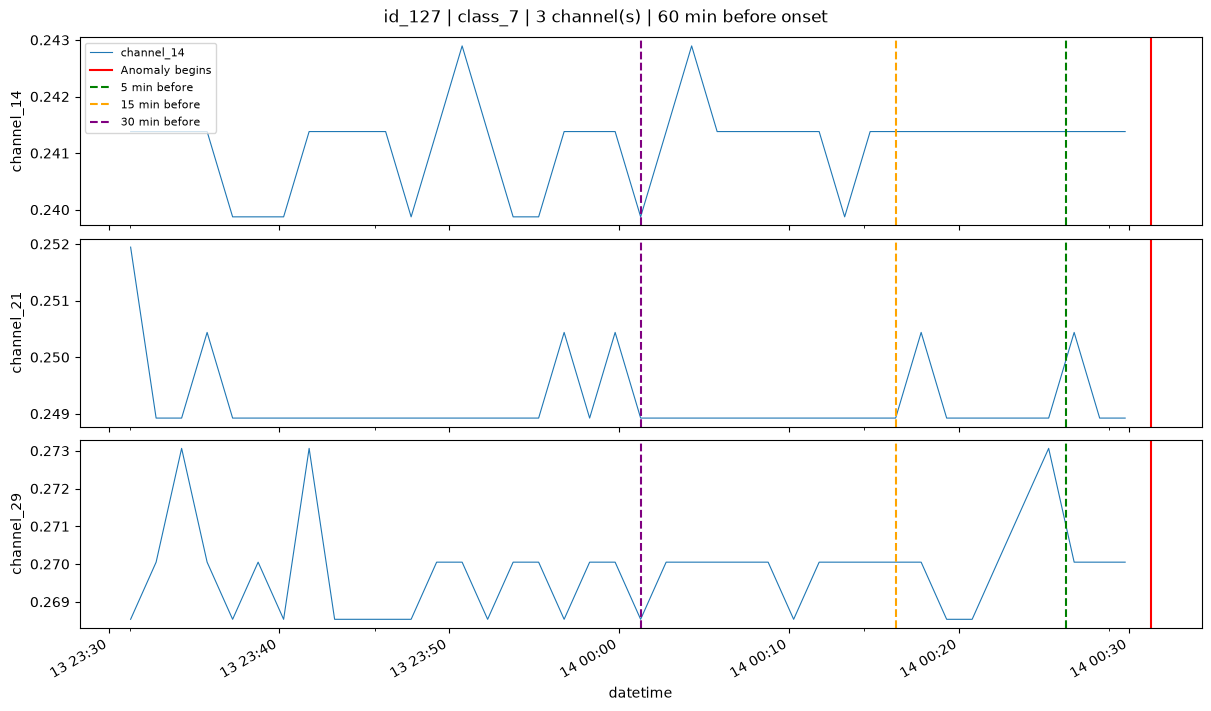

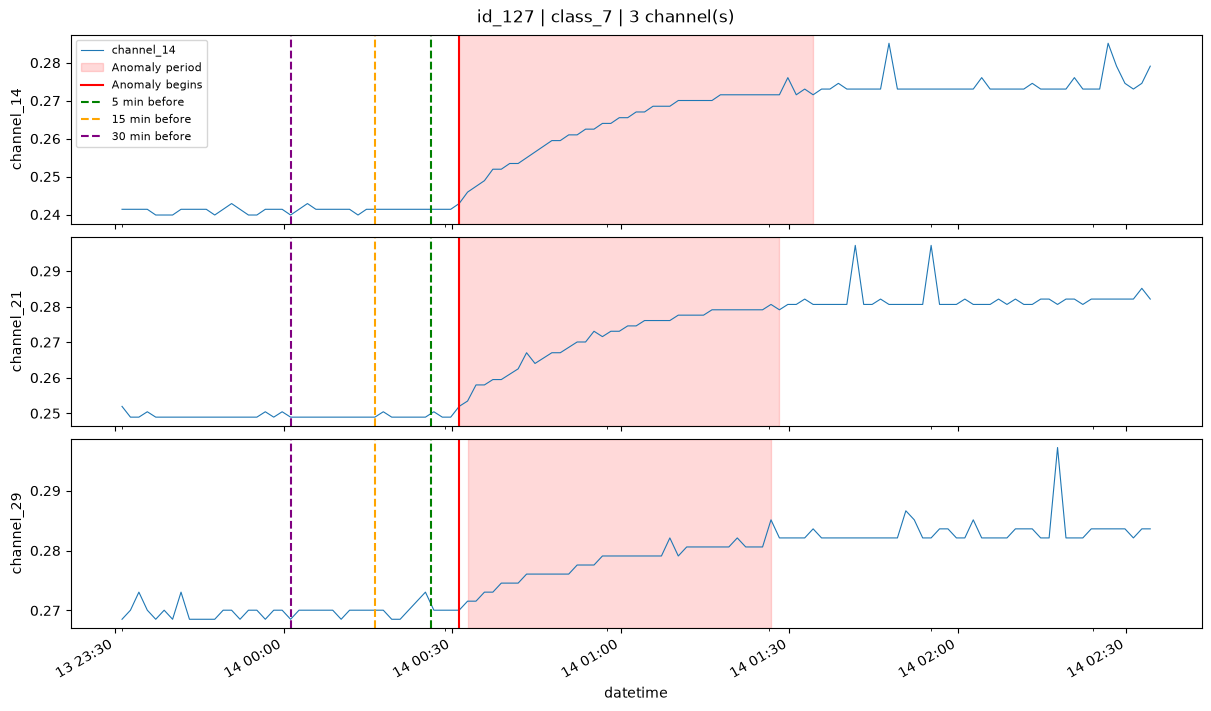

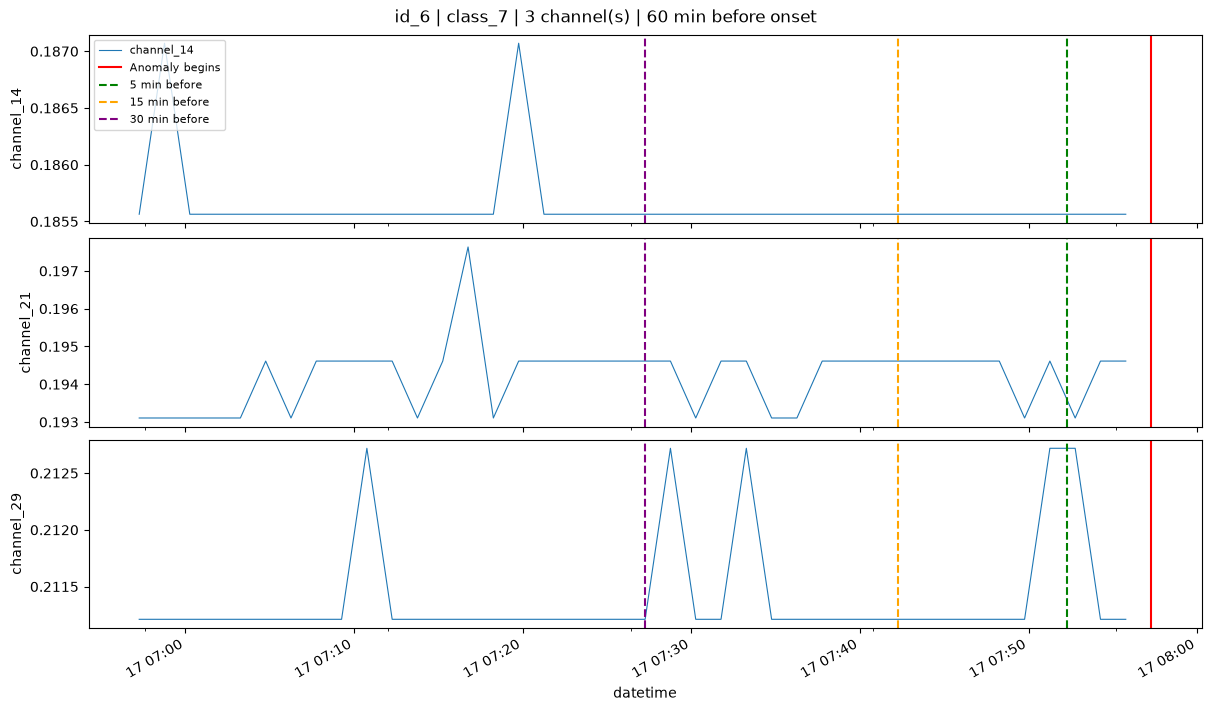

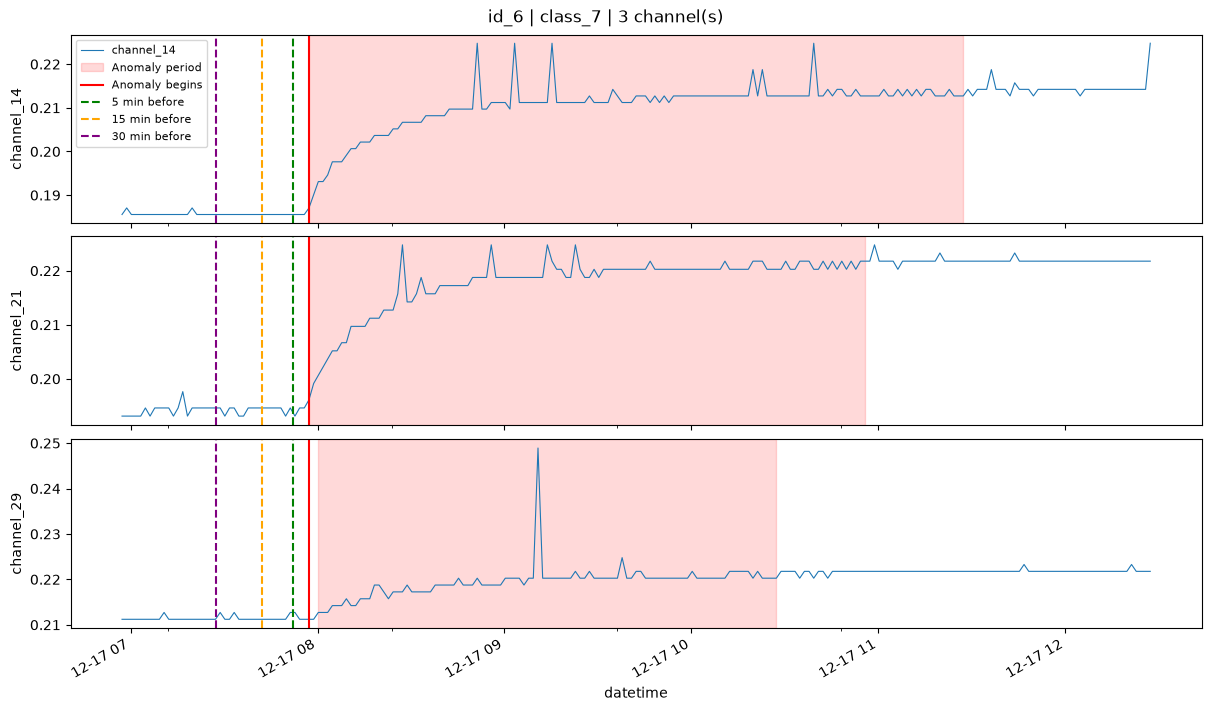

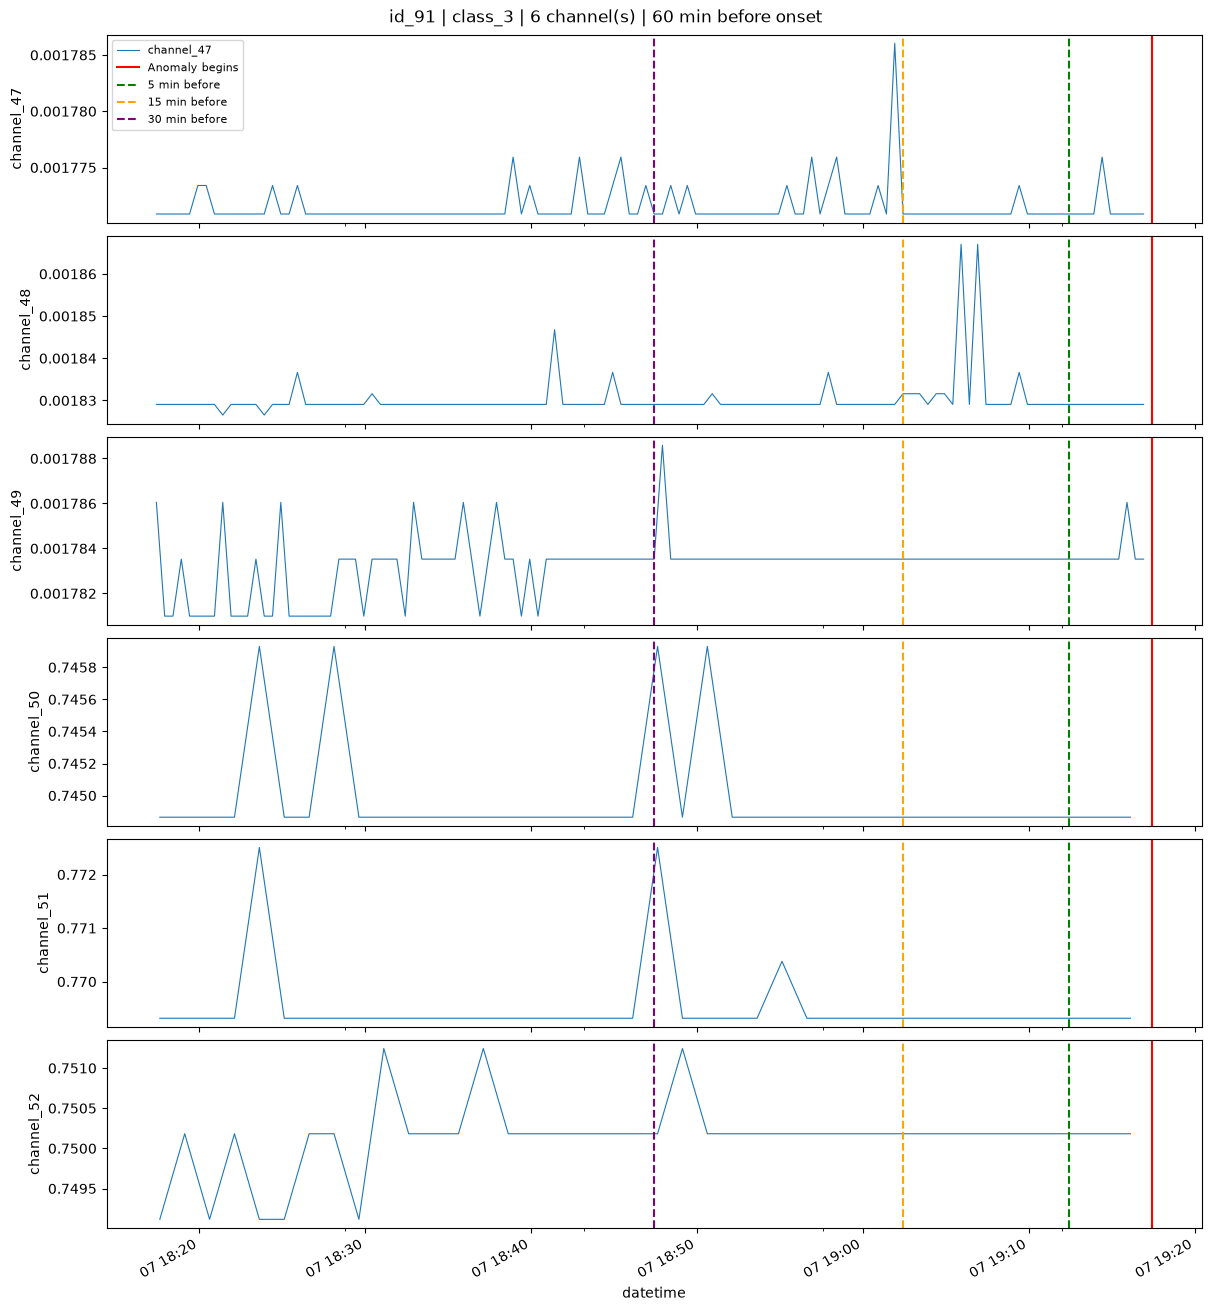

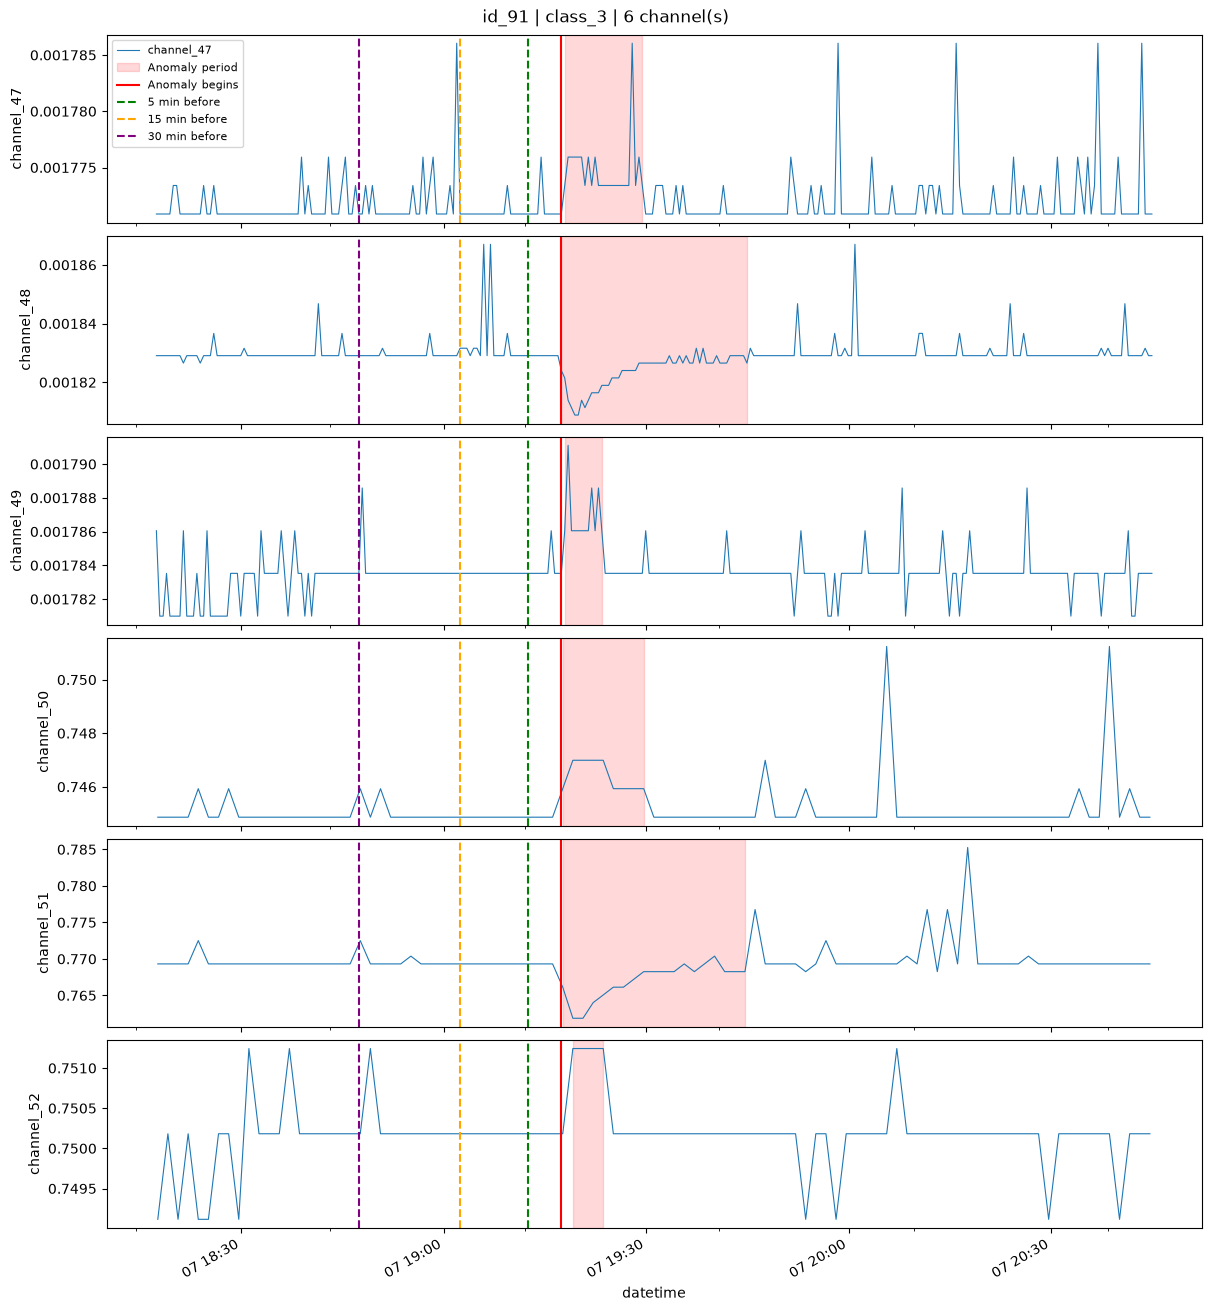

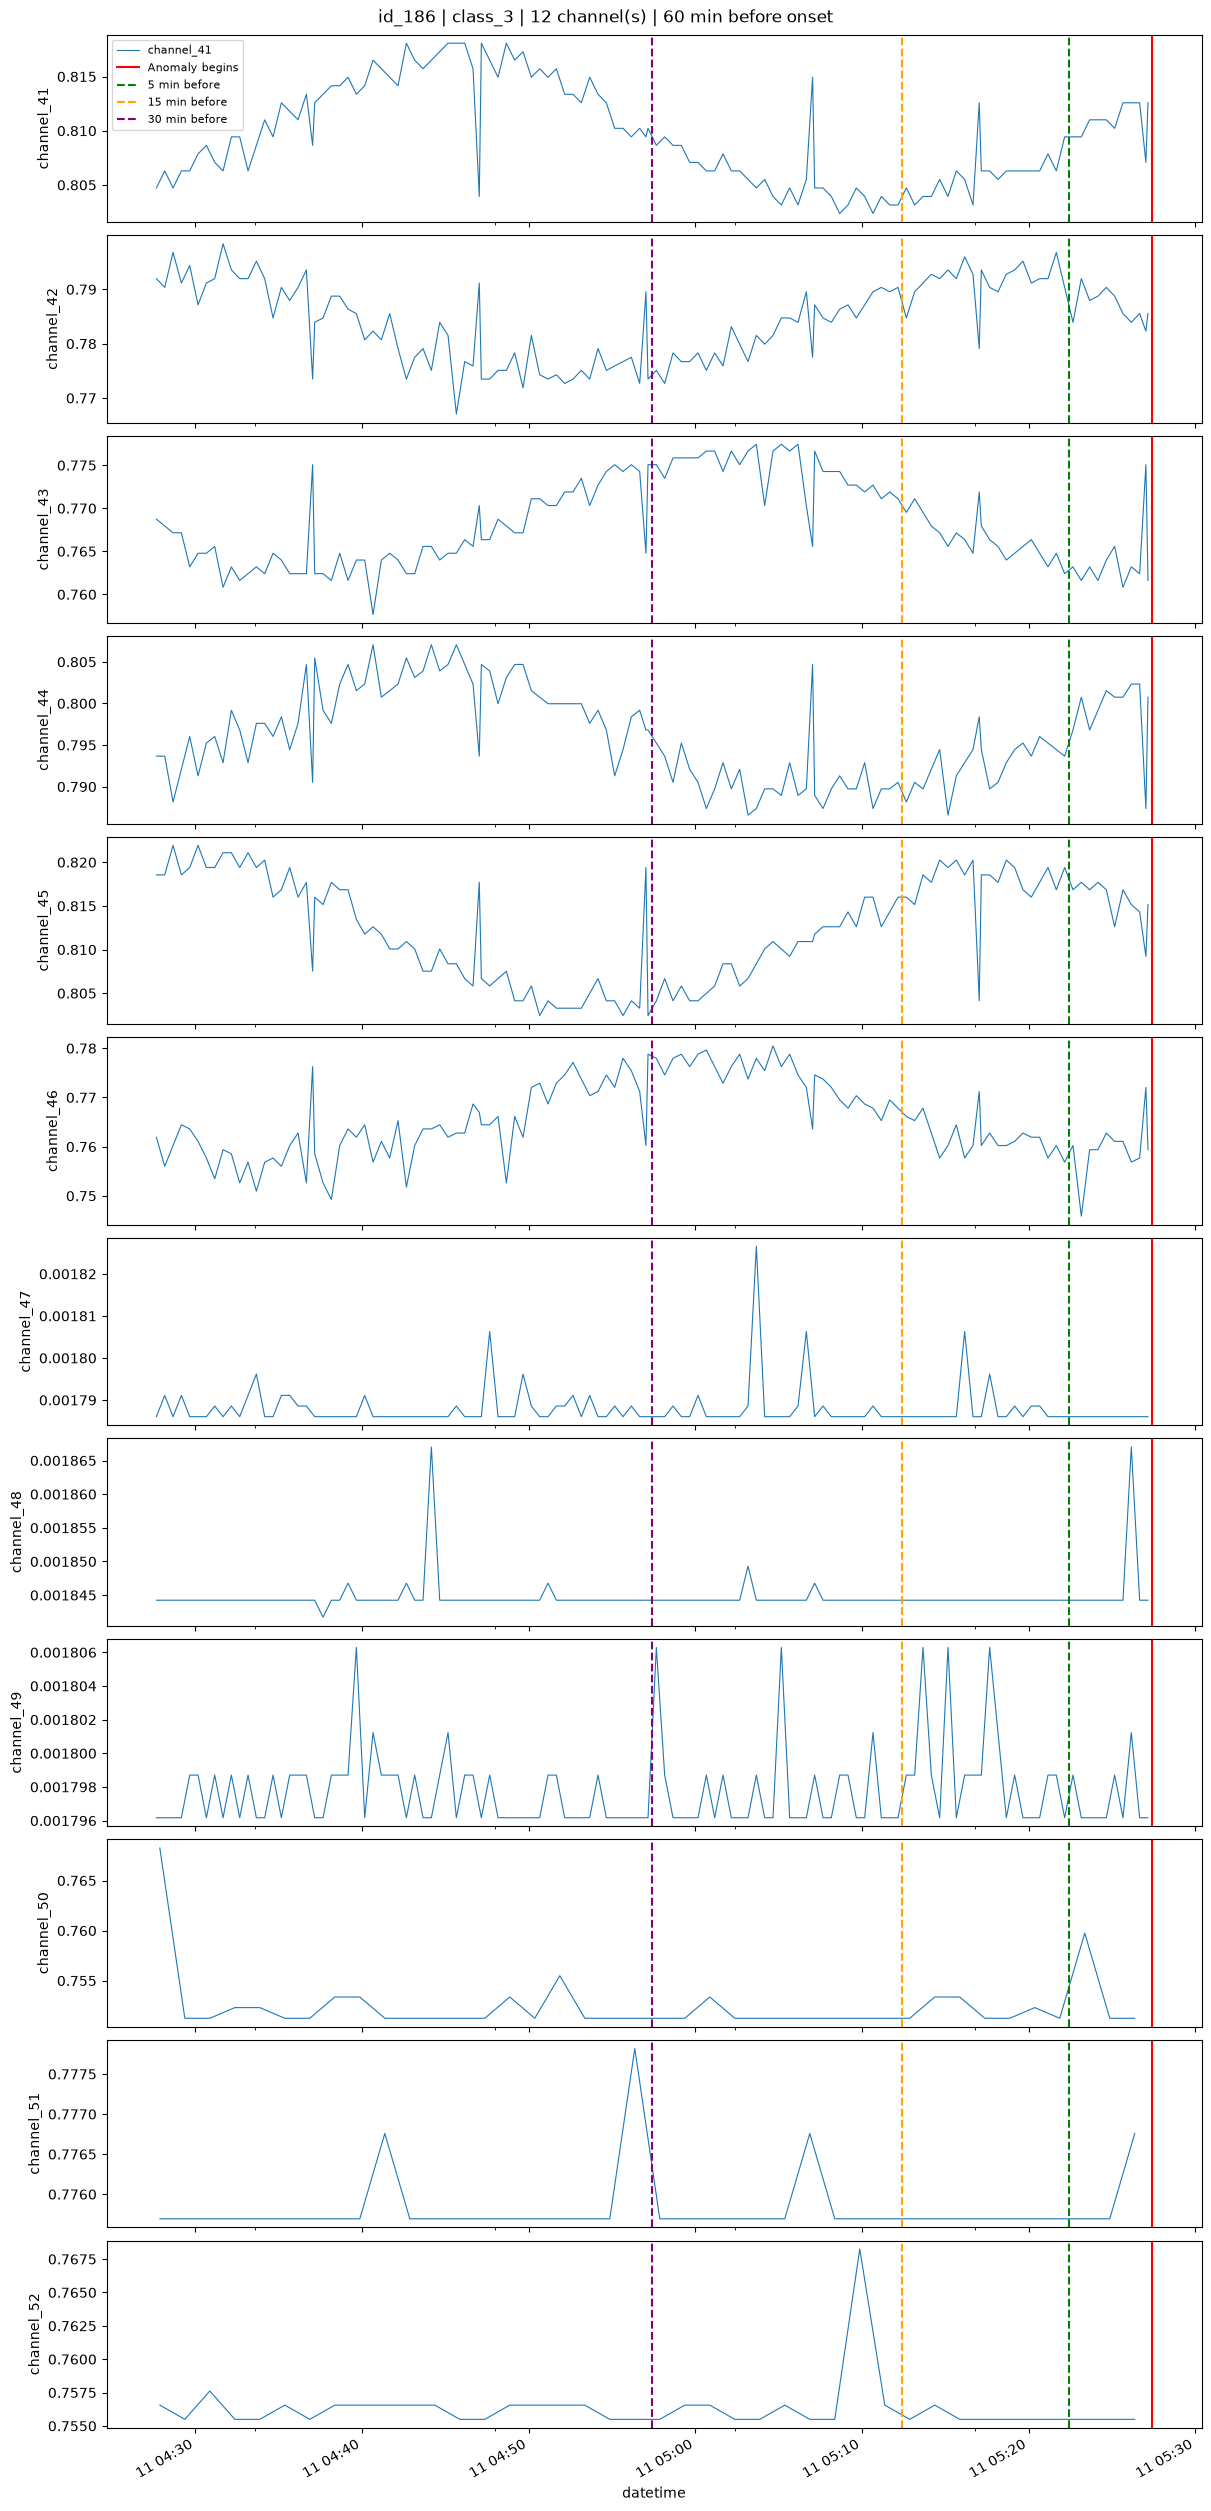

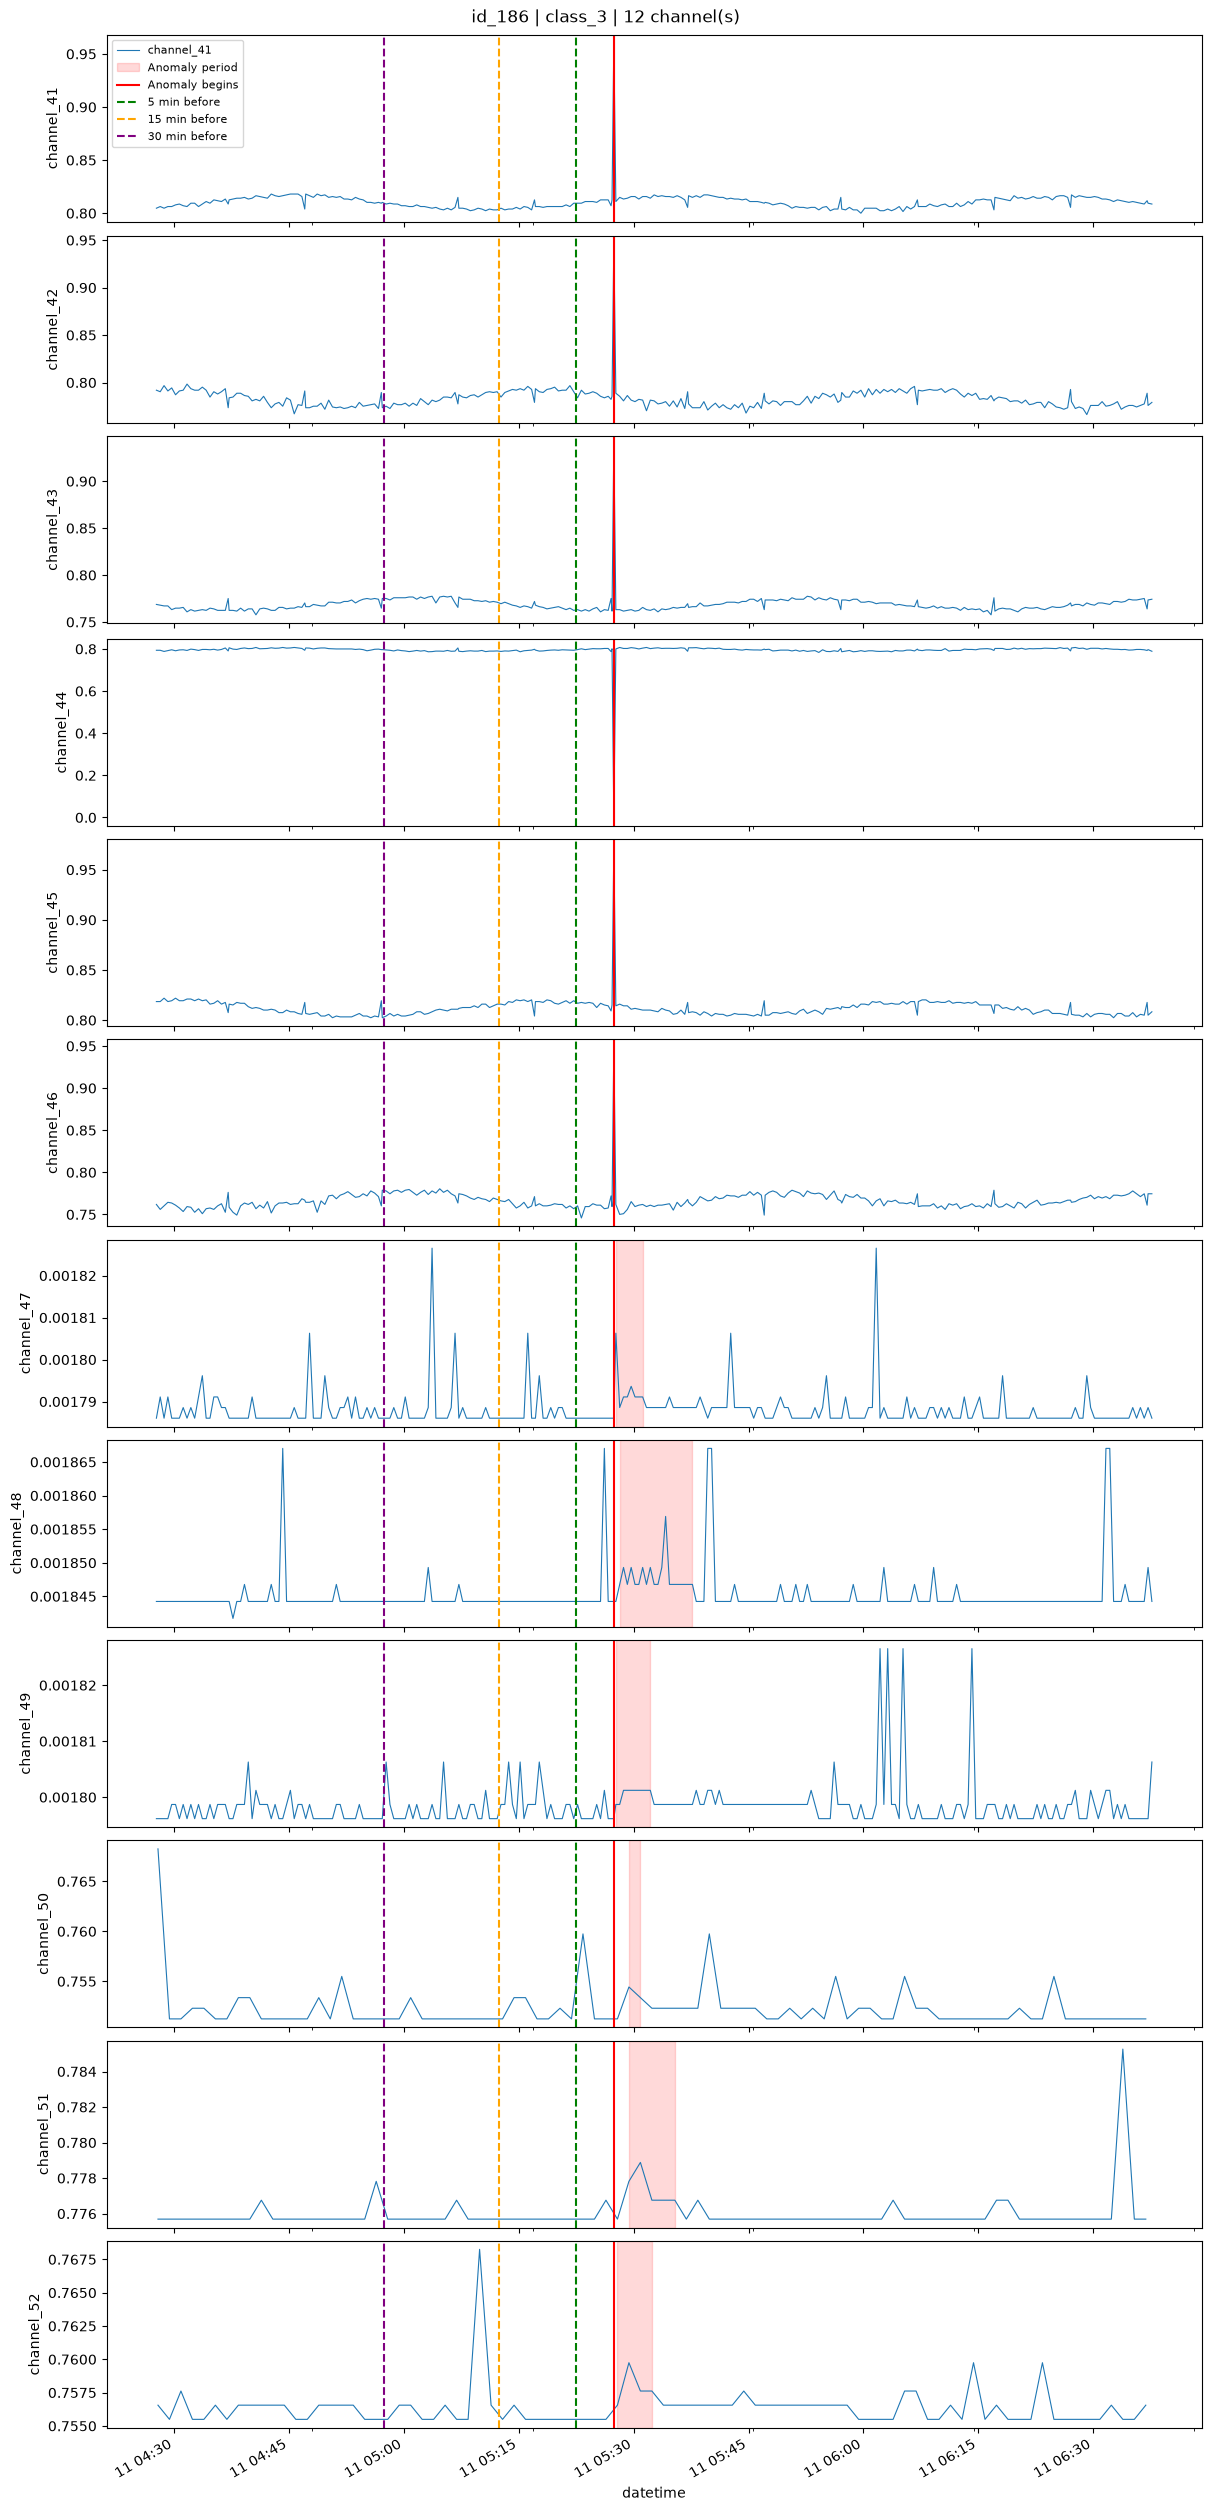

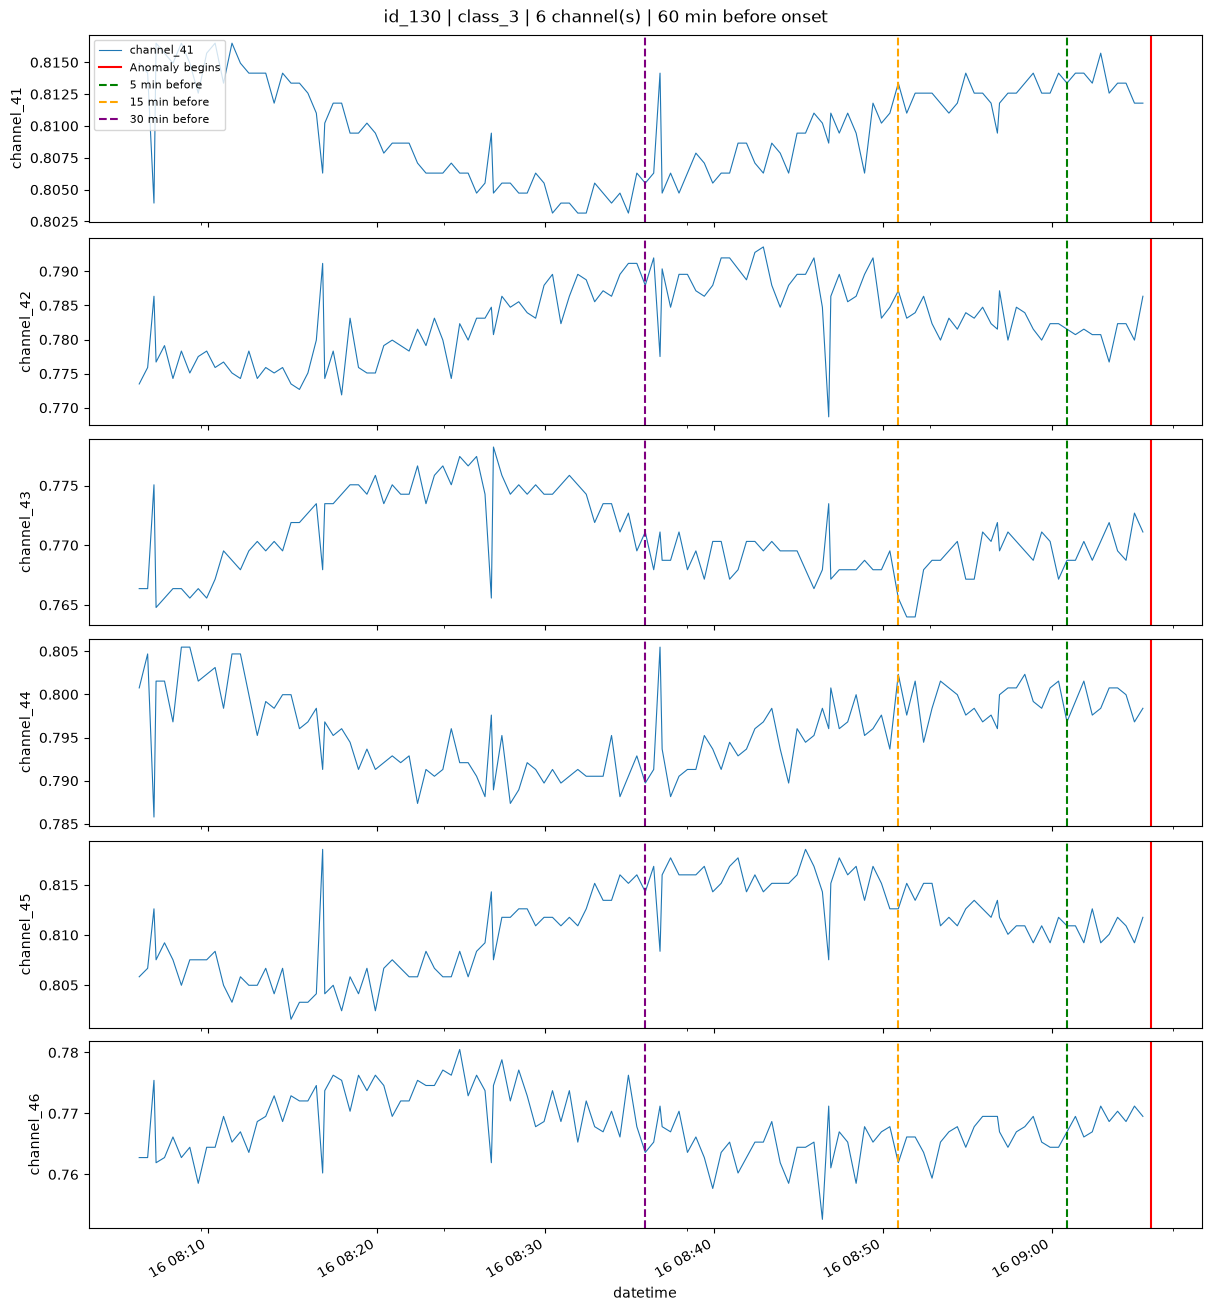

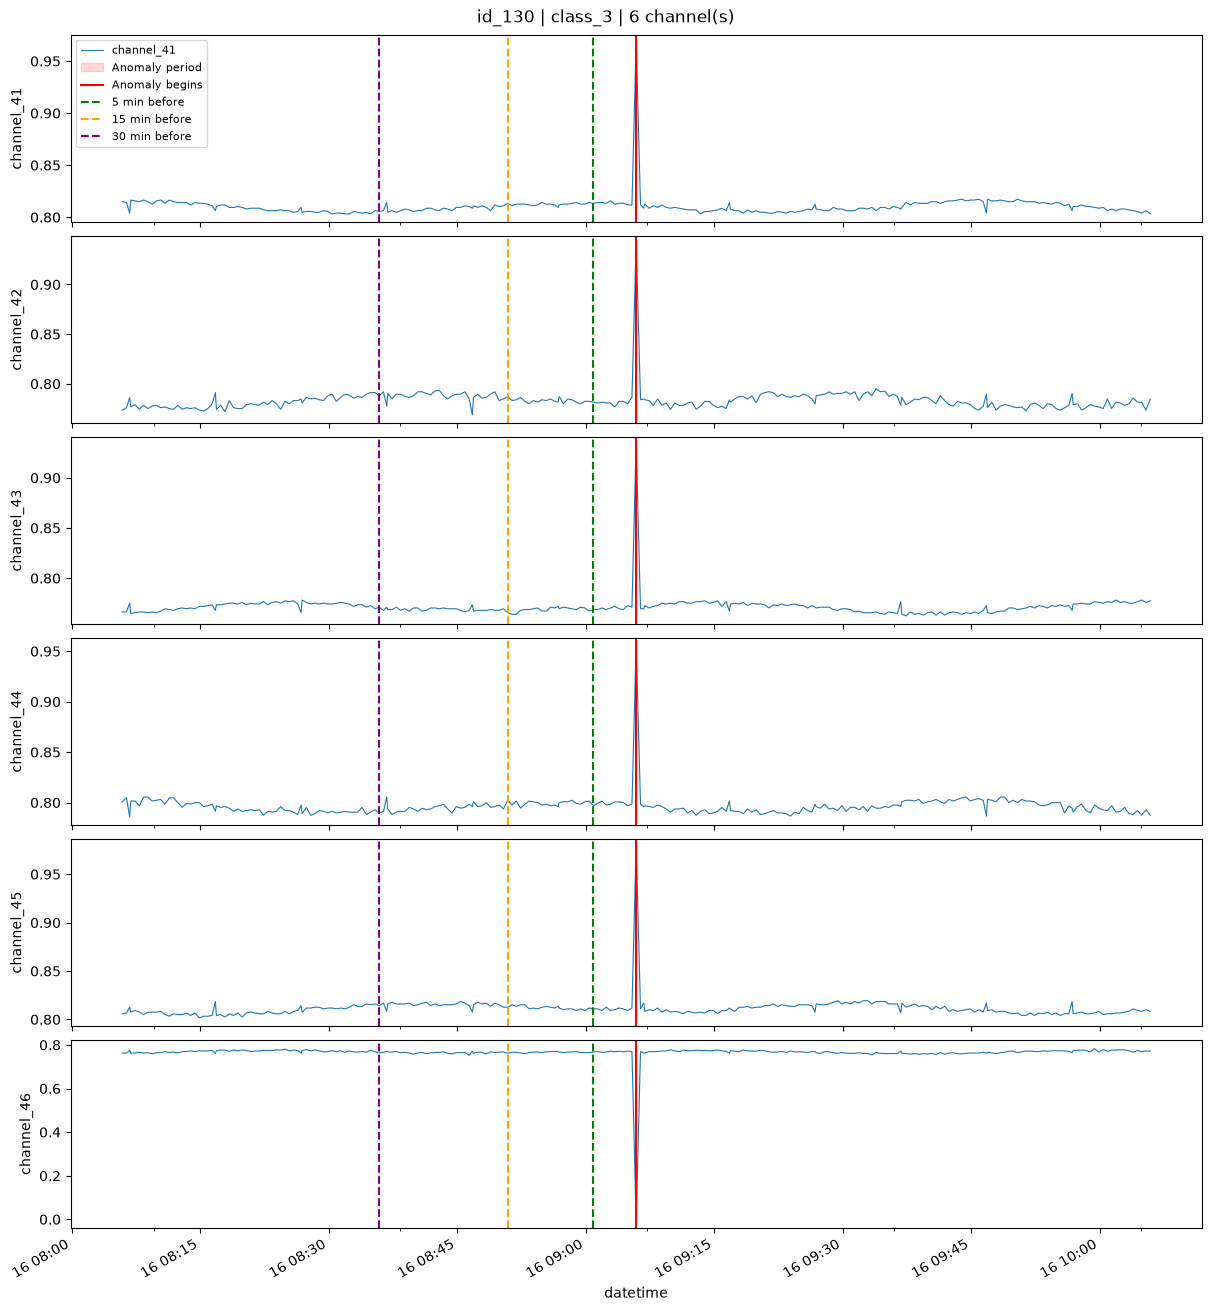

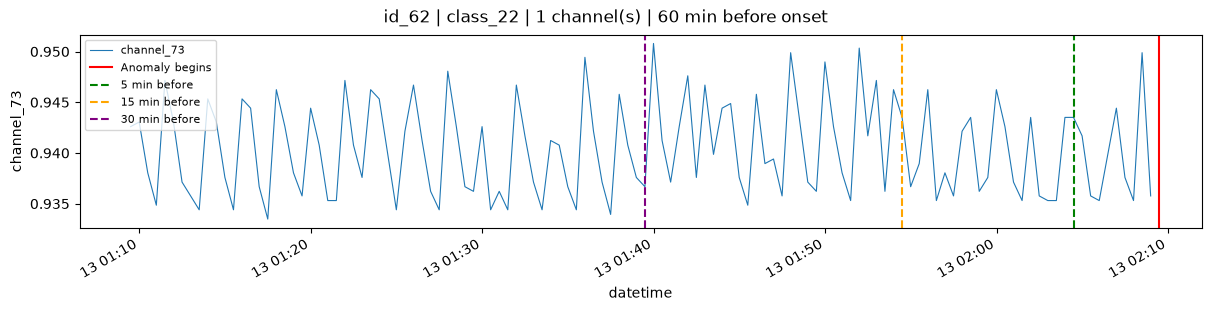

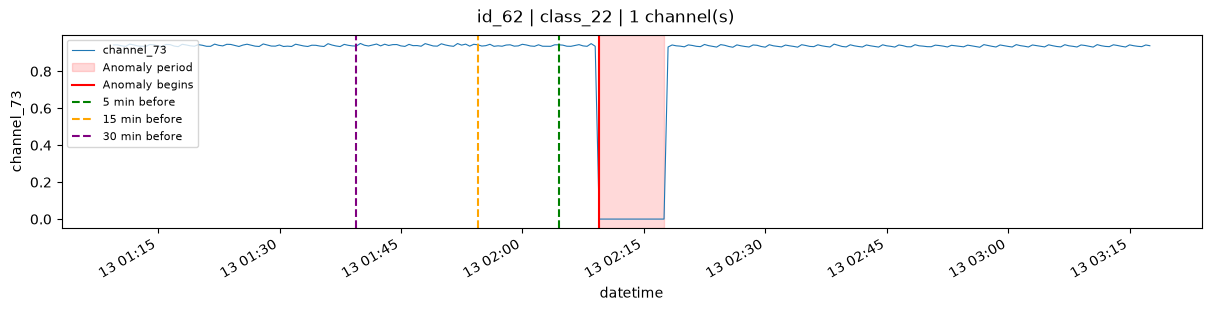

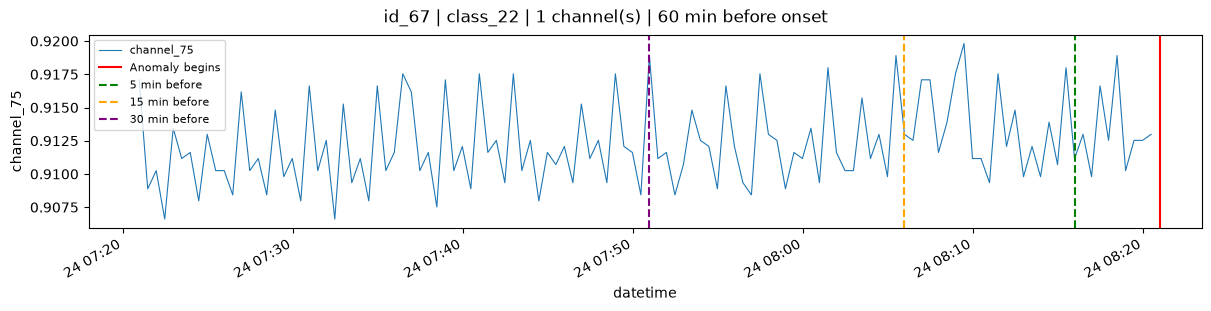

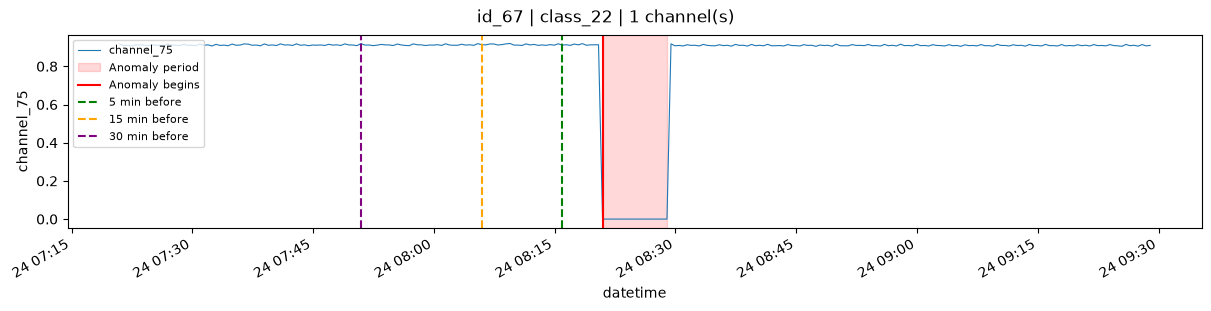

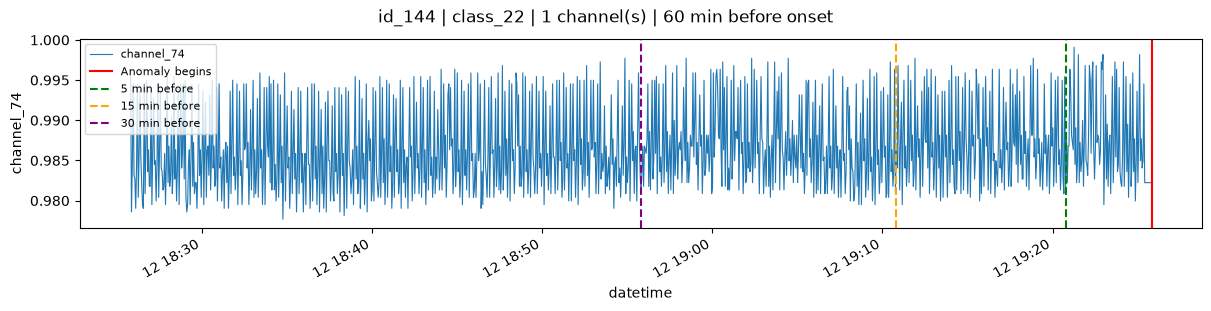

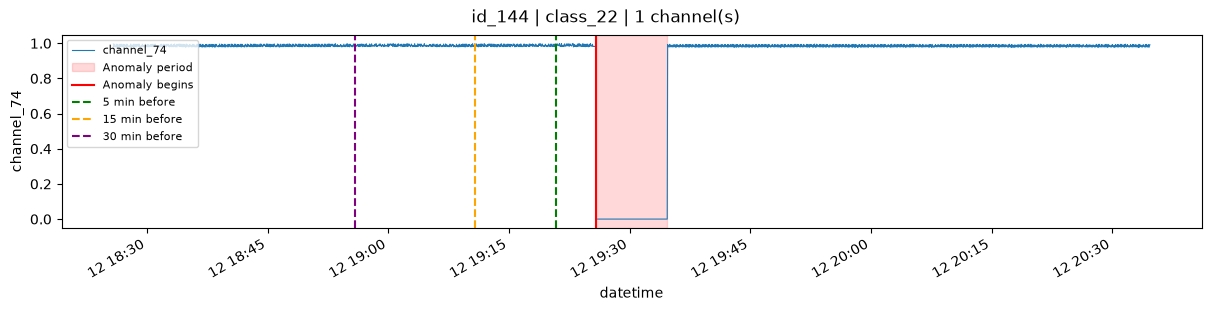

In [6]:
# Draw the anomaly start (red) and the 5/15/30 min marks before it (dashed)
def mark_onset(ax, start):
    ax.axvline(start, color='red', label='Anomaly begins')
    for m, c in [(5, 'green'), (15, 'orange'), (30, 'purple')]:
        ax.axvline(start - pd.Timedelta(minutes=m), color=c, ls='--', label=f'{m} min before')

stats, skipped = [], []

for _, a in anomalies.iterrows():
    rows = labels[labels.ID == a.ID]
    # Onset = earliest start over all affected channels, so every channel uses the same reference time
    start = rows.StartTime.min().tz_localize(None)
    end = rows.EndTime.max().tz_localize(None)
    pre_start = start - pd.Timedelta(minutes=60)

    pre_data, full_data = {}, {}
    for channel in rows.Channel.unique():
        telemetry = pd.read_pickle(f'{DATA_DIR}/channels/{channel}.zip')[channel]

        # 60 minutes before onset (onset itself excluded)
        pre = telemetry.loc[pre_start:start]
        pre = pre[pre.index < start]

        # Skip this channel if the window is too sparse or has a large gap (edges included)
        max_gap = pd.Series([pre_start, *pre.index, start]).diff().max()
        if len(pre) < MIN_SAMPLES or max_gap > MAX_GAP:
            skipped.append({'ID': a.ID, 'Channel': channel, 'Class': a.Class,
                            'Reason': f'{len(pre)} samples, largest gap {max_gap}'})
            continue

        # Basic statistics of the pre-anomaly window (slope in units per minute)
        minutes = (pre.index - start).total_seconds() / 60
        stats.append({'ID': a.ID, 'Channel': channel, 'Class': a.Class, 'Start': start,
                      'Samples': len(pre), 'Mean': pre.mean(), 'Std': pre.std(),
                      'Min': pre.min(), 'Max': pre.max(),
                      'Slope': np.polyfit(minutes, pre.values, 1)[0]})

        pre_data[channel] = pre
        full_data[channel] = telemetry.loc[pre_start : end + pd.Timedelta(minutes=60)]

    if not pre_data:
        continue
    n = len(pre_data)
    title = f'{a.ID} | {a.Class} | {n} channel(s)'

    # Plot 1: only the 60 minutes before onset, one panel per channel
    fig, axes = plt.subplots(n, 1, figsize=(12, 2 * n + 1), sharex=True, squeeze=False, layout='constrained')
    for ax, (channel, pre) in zip(axes[:, 0], pre_data.items()):
        pre.plot(ax=ax, lw=0.8)
        mark_onset(ax, start)
        ax.set_ylabel(channel)
    axes[0, 0].legend(loc='upper left', fontsize=8)
    fig.suptitle(f'{title} | 60 min before onset')
    plt.savefig(f'{PRE_DIR}/{a.ID}.png', dpi=110, bbox_inches='tight')
    plt.show()

    # Plot 2: before, during and after the anomaly, shading each channel's own labeled period
    fig, axes = plt.subplots(n, 1, figsize=(12, 2 * n + 1), sharex=True, squeeze=False, layout='constrained')
    for ax, (channel, full) in zip(axes[:, 0], full_data.items()):
        full.plot(ax=ax, lw=0.8)
        for _, r in rows[rows.Channel == channel].iterrows():
            ax.axvspan(r.StartTime.tz_localize(None), r.EndTime.tz_localize(None),
                       color='red', alpha=0.15, label='Anomaly period')
        mark_onset(ax, start)
        ax.set_ylabel(channel)
    axes[0, 0].legend(loc='upper left', fontsize=8)
    fig.suptitle(title)
    plt.savefig(f'{FULL_DIR}/{a.ID}.png', dpi=110, bbox_inches='tight')
    plt.show()

In [7]:
# Save statistics (one row per anomaly and channel) and report skipped channels
stats = pd.DataFrame(stats)
stats.to_csv('pre_anomaly_stats.csv', index=False)
print(f'Saved statistics for {len(stats)} channels across {stats.ID.nunique()} anomalies, skipped {len(skipped)} channels')
print(pd.DataFrame(skipped).to_string() if skipped else 'None skipped')
stats

Saved statistics for 39 channels across 10 anomalies, skipped 0 channels
None skipped


,ID,Channel,Class,Start,Samples,Mean,Std,Min,Max,Slope
0,id_137,channel_14,class_7,2009-09-21 09:16:30.189,40,0.330403,0.001369,0.329980,0.335057,2.285939e-05
1,id_137,channel_21,class_7,2009-09-21 09:16:30.189,40,0.340297,0.000515,0.340128,0.341822,-6.359022e-06
2,id_137,channel_29,class_7,2009-09-21 09:16:30.189,40,0.342160,0.001223,0.340128,0.348588,1.774445e-05
3,id_161,channel_14,class_7,2011-08-16 14:52:30.084,40,0.312553,0.000673,0.312289,0.315304,3.675935e-06
4,id_161,channel_21,class_7,2011-08-16 14:52:30.084,40,0.320086,0.000903,0.319832,0.324909,-2.753479e-06
5,id_161,channel_29,class_7,2011-08-16 14:52:30.084,40,0.323892,0.002194,0.321526,0.335057,-4.373635e-07
6,id_127,channel_14,class_7,2008-03-14 00:31:15.270,40,0.241155,0.000729,0.239874,0.242895,8.856598e-06
7,id_127,channel_21,class_7,2008-03-14 00:31:15.270,40,0.249188,0.000675,0.248923,0.251944,-5.569379e-06
8,id_127,channel_29,class_7,2008-03-14 00:31:15.270,40,0.269822,0.001211,0.268536,0.273064,9.855744e-06
9,id_6,channel_14,class_7,2001-12-17 07:57:15.558,40,0.185639,0.000333,0.185564,0.187071,-4.335718e-06
